# Contribuição D: falsos positivos por grupo (ToxSyn-PT e HateCheck-PT)

**Pergunta (RQ4):** os modelos marcam como tóxicas mais frases inofensivas sobre pessoas com deficiência do que sobre outros grupos, em corpora que não dependem dos nossos templates?

**Critério:** "o padrão aparece" quando a taxa de falso positivo de pessoas com deficiência (PcD) no teste do ToxSyn-PT é maior que a da categoria "neutral" (frases sem grupo-alvo), com correção de Holm. Também reportamos a posição de PcD entre os nove grupos, sem exigir que seja a maior.

**Entrada:** `data_externa/toxsyn_pt_test.parquet`, `hatecheck_pt_test.parquet`, `toxiguardrail_hatecheck_portuguese_eval.parquet` (para conferência) e, em `results`, `thresholds.json` e `c4_sensibilidade_limiar_v1.1_por_termo.csv`.

**Saída (em `results`):** `d_toxsyn_nao_toxicas_scores.csv`, `d_hatecheck_scores.csv`, `d_fpr_toxsyn_por_grupo.csv`, `d_comparacoes_toxsyn_pcd.csv`, `d_fpr_hatecheck_por_grupo.csv`, `d_comparacoes_hatecheck_pcd.csv` e a figura `d_fpr_toxsyn_por_grupo.png`.

**Precisa de GPU:** antes de rodar, **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4**.

A variável `RODAR_TOXSYN_COMPLETO` (célula 1) vem como `False`: roda só o teste do ToxSyn-PT, que é a análise principal. Com `True`, roda também as 28 mil frases não tóxicas do treino, como análise de sensibilidade. Isso demora bem mais.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np, pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ROOT = "/content/drive/MyDrive/JIS - capacitismo"
BASE = f"{ROOT}/data_externa"
OUT  = f"{ROOT}/results"
SEED = 42
RODAR_TOXSYN_COMPLETO = False

with open(f"{OUT}/thresholds.json") as f:
    thresholds = json.load(f)
MODELS = {"tox1": ("BERTimbau toxic", "dougtrajano/toxic-comment-classification", "bertimbau"),
          "tox2": ("ToxiGuardrail-PT", "nicholasKluge/ToxiGuardrailPT", "guardrail")}
device = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("dispositivo:", device, "| limiares:", thresholds)

@torch.no_grad()
def score_texts(model_name, kind, texts, batch_size=32, max_length=512):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).to(device).eval()
    if kind == "bertimbau":
        off_id = {v: k for k, v in model.config.id2label.items()}["OFFENSIVE"]
    texts = [str(t) for t in texts]
    order = np.argsort([len(t) for t in texts])
    scores = np.empty(len(texts))
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        enc = tok([texts[j] for j in idx], padding=True, truncation=True,
                  max_length=max_length, return_tensors="pt").to(device)
        logits = model(**enc).logits
        if kind == "bertimbau":
            s = torch.softmax(logits, dim=-1)[:, off_id]
        else:
            s = 1 - torch.sigmoid(logits.squeeze(-1))
        scores[idx] = s.float().cpu().numpy()
    n_truncados = sum(len(ids) > max_length for ids in tok([texts[j] for j in order[-200:]])["input_ids"])
    del model
    torch.cuda.empty_cache()
    return scores, n_truncados

Mounted at /content/drive
dispositivo: cuda | limiares: {'tox1': {'padrao_0.5': 0.5, 'youden': 0.7966679930686951, 'fpr_5': 0.8413420140743255}, 'tox2': {'padrao_0.5': 0.5, 'youden': 0.4324200749397278, 'fpr_5': 0.8765263080596923}}


## 1. Dados

Ficam só as frases não tóxicas do ToxSyn-PT. No teste, são 269 de PcD e 212 da categoria "neutral". O grupo PcD usa quase só a expressão "pessoas com deficiência" (238 das 269 frases): é a forma institucional, que teve efeito pequeno na PSA da v1.1.

No HateCheck-PT, a análise usa as frases neutras e positivas que mencionam um grupo (funcionalidades F16 e F17): de 49 a 51 por grupo, 51 de PcD.

In [2]:
partes = [pd.read_parquet(f"{BASE}/toxsyn_pt_test.parquet").assign(particao="teste")]
if RODAR_TOXSYN_COMPLETO:
    partes.append(pd.read_parquet(f"{BASE}/toxsyn_pt_train.parquet").assign(particao="treino"))
toxsyn = pd.concat(partes, ignore_index=True)
toxsyn["group"] = toxsyn.group.str.lower()
toxsyn_nt = toxsyn[toxsyn.is_toxic == 0].reset_index(drop=True)

print("frases não tóxicas por grupo:")
print(toxsyn_nt.groupby(["particao", "group"]).size().unstack(0))

pcd = toxsyn_nt[(toxsyn_nt.group == "pessoas com deficiência") & (toxsyn_nt.particao == "teste")]
print("\nPcD no teste:", len(pcd), "frases não tóxicas |",
      "com a expressão 'pessoas com deficiência':", int(pcd.text.str.lower().str.contains("pessoas com deficiência").sum()))

hatecheck = pd.read_parquet(f"{BASE}/hatecheck_pt_test.parquet")
print("\nHateCheck-PT:", len(hatecheck), "casos |",
      "frases neutras ou positivas com grupo (F16 e F17):", int(hatecheck.functionality.isin(["ident_neutral_nh", "ident_pos_nh"]).sum()))

frases não tóxicas por grupo:
particao                 teste
group                         
idosos                     257
imigrante                  249
judeus                     269
lgbtqia+                   285
mulheres                   248
muçulmanos                 285
negros                     299
neutral                    212
pessoas com deficiência    269
povos indígenas            292

PcD no teste: 269 frases não tóxicas | com a expressão 'pessoas com deficiência': 238

HateCheck-PT: 3691 casos | frases neutras ou positivas com grupo (F16 e F17): 353


## 2. Scores dos dois modelos

Os textos são cortados em 512 tokens (o notebook da v1 usava 128, mas o ToxSyn-PT tem textos de até 236 palavras). A célula informa quantos dos textos mais longos passaram desse limite.

**Conferência:** no HateCheck-PT, as decisões do ToxiGuardrail-PT têm de coincidir com as dos scores que o autor do modelo publicou. Se a concordância ficar longe de 100%, algo no uso do modelo está diferente e é preciso parar e verificar.

In [3]:
for key, (name, model_id, kind) in MODELS.items():
    toxsyn_nt[f"{key}_score"], trunc = score_texts(model_id, kind, toxsyn_nt.text.tolist())
    hatecheck[f"{key}_score"], _ = score_texts(model_id, kind, hatecheck.test_case.tolist())
    print(f"{name}: textos do ToxSyn-PT cortados em 512 tokens (entre os 200 mais longos): {trunc}")

toxsyn_nt.to_csv(f"{OUT}/d_toxsyn_nao_toxicas_scores.csv", index=False)
hatecheck.to_csv(f"{OUT}/d_hatecheck_scores.csv", index=False)

autor = pd.read_parquet(f"{BASE}/toxiguardrail_hatecheck_portuguese_eval.parquet")
assert (autor.text.values == hatecheck.test_case.values).all()
logit_col = [c for c in autor.columns if c not in ("text", "label")][0]
concorda = ((autor[logit_col] < 0).values == (hatecheck.tox2_score >= 0.5).values).mean()
print(f"\nConferência: decisão do ToxiGuardrail-PT igual à do autor em {concorda:.1%} dos casos do HateCheck-PT (esperado: perto de 100%)")

config.json:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/678k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ToxiGuardrail-PT: textos do ToxSyn-PT cortados em 512 tokens (entre os 200 mais longos): 0

Conferência: decisão do ToxiGuardrail-PT igual à do autor em 100.0% dos casos do HateCheck-PT (esperado: perto de 100%)


## 3. Taxa de falso positivo por grupo no ToxSyn-PT

Para cada modelo, limiar e grupo: a fração de frases não tóxicas que o modelo marca como tóxicas, com intervalo de 95% por bootstrap (10 mil reamostragens, semente fixa).

Comparações: PcD contra a categoria "neutral" e contra cada um dos outros grupos. Para cada comparação: a diferença das taxas, com intervalo por bootstrap, e o teste exato de Fisher, com correção de Holm.

In [4]:
from scipy.stats import fisher_exact

def holm(pvalues):
    p = np.asarray(pvalues, dtype=float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(running, 1.0)
    return adj

def boot_ci(k, n, rng, B=10_000):
    return np.percentile(rng.binomial(n, k / n, B) / n, [2.5, 97.5])

def fpr_table(df, group_col, ref_group, corpus):
    rng = np.random.default_rng(SEED)
    rows, comps = [], []
    for key, (name, _, _) in MODELS.items():
        for thr_name, thr in thresholds[key].items():
            fp = (df[f"{key}_score"] >= thr).groupby(df[group_col]).agg(["sum", "size"])
            for g, r in fp.iterrows():
                lo, hi = boot_ci(r["sum"], r["size"], rng)
                rows.append({"corpus": corpus, "modelo": name, "limiar": thr_name, "grupo": g, "n": int(r["size"]),
                             "falsos_positivos": int(r["sum"]), "taxa_fp": r["sum"] / r["size"], "ic95_inf": lo, "ic95_sup": hi})
            a, n1 = fp.loc[ref_group]
            outros = [g for g in fp.index if g != ref_group]
            ps = []
            for g in outros:
                b, n2 = fp.loc[g]
                ps.append(fisher_exact([[a, n1 - a], [b, n2 - b]])[1])
                diff = rng.binomial(n1, a / n1, 10_000) / n1 - rng.binomial(n2, b / n2, 10_000) / n2
                comps.append({"corpus": corpus, "modelo": name, "limiar": thr_name, "comparacao": f"{ref_group} x {g}",
                              "diferenca": a / n1 - b / n2, "ic95_inf": np.percentile(diff, 2.5), "ic95_sup": np.percentile(diff, 97.5)})
            for c, p, ph in zip(comps[-len(outros):], ps, holm(ps)):
                c["p"] = p; c["p_holm"] = ph
    return pd.DataFrame(rows), pd.DataFrame(comps)

PCD = "pessoas com deficiência"
fpr_ts, comp_ts = [], []
for particao, d in toxsyn_nt.groupby("particao"):
    f, c = fpr_table(d, "group", PCD, f"ToxSyn-PT ({particao})")
    fpr_ts.append(f); comp_ts.append(c)
fpr_ts, comp_ts = pd.concat(fpr_ts), pd.concat(comp_ts)
fpr_ts.to_csv(f"{OUT}/d_fpr_toxsyn_por_grupo.csv", index=False)
comp_ts.to_csv(f"{OUT}/d_comparacoes_toxsyn_pcd.csv", index=False)

ORDEM = ["padrao_0.5", "youden", "fpr_5"]
teste = fpr_ts[fpr_ts.corpus == "ToxSyn-PT (teste)"]
for name in teste.modelo.unique():
    t = teste[teste.modelo == name]
    print(f"\n===== {name}: taxa de falso positivo por grupo (ToxSyn-PT, teste)")
    print(t.pivot(index="grupo", columns="limiar", values="taxa_fp")[ORDEM].sort_values("fpr_5", ascending=False).round(3))
    c = comp_ts[(comp_ts.corpus == "ToxSyn-PT (teste)") & (comp_ts.modelo == name) & (comp_ts.comparacao == f"{PCD} x neutral")]
    print("PcD x neutral:", c[["limiar", "diferenca", "ic95_inf", "ic95_sup", "p_holm"]].round(4).to_string(index=False))


===== BERTimbau toxic: taxa de falso positivo por grupo (ToxSyn-PT, teste)
limiar                   padrao_0.5  youden  fpr_5
grupo                                             
neutral                       0.057   0.009  0.005
idosos                        0.004   0.000  0.000
imigrante                     0.000   0.000  0.000
judeus                        0.000   0.000  0.000
mulheres                      0.012   0.004  0.000
lgbtqia+                      0.186   0.000  0.000
muçulmanos                    0.004   0.000  0.000
negros                        0.003   0.000  0.000
pessoas com deficiência       0.000   0.000  0.000
povos indígenas               0.003   0.000  0.000
PcD x neutral:     limiar  diferenca  ic95_inf  ic95_sup  p_holm
padrao_0.5    -0.0566   -0.0896   -0.0283  0.0004
    youden    -0.0094   -0.0236    0.0000  1.0000
     fpr_5    -0.0047   -0.0142    0.0000  1.0000

===== ToxiGuardrail-PT: taxa de falso positivo por grupo (ToxSyn-PT, teste)
limiar              

## 4. HateCheck-PT: frases neutras e positivas por grupo

Mesma conta nas funcionalidades F16 e F17. O HateCheck-PT não tem categoria sem grupo, então PcD é comparado com cada um dos outros seis grupos.

**Conferência:** pelos scores publicados pelo autor, o ToxiGuardrail-PT marca como tóxicas 35% das frases neutras ou positivas sobre "deficientes" com o limiar 0,5. O resultado desta célula deve dar o mesmo.

In [5]:
F16_F17 = hatecheck[hatecheck.functionality.isin(["ident_neutral_nh", "ident_pos_nh"])]
fpr_hc, comp_hc = fpr_table(F16_F17, "target_ident", "disabled people", "HateCheck-PT (F16 e F17)")
fpr_hc.to_csv(f"{OUT}/d_fpr_hatecheck_por_grupo.csv", index=False)
comp_hc.to_csv(f"{OUT}/d_comparacoes_hatecheck_pcd.csv", index=False)

for name in fpr_hc.modelo.unique():
    t = fpr_hc[fpr_hc.modelo == name]
    print(f"\n===== {name}: taxa de falso positivo nas frases neutras e positivas (HateCheck-PT)")
    print(t.pivot(index="grupo", columns="limiar", values="taxa_fp")[ORDEM].sort_values("padrao_0.5", ascending=False).round(3))


===== BERTimbau toxic: taxa de falso positivo nas frases neutras e positivas (HateCheck-PT)
limiar             padrao_0.5  youden  fpr_5
grupo                                       
gay people              1.000   0.157  0.118
disabled people         0.843   0.412  0.373
black people            0.235   0.020  0.020
trans people            0.204   0.000  0.000
jews                    0.176   0.000  0.000
indigenous people       0.020   0.000  0.000
women                   0.000   0.000  0.000

===== ToxiGuardrail-PT: taxa de falso positivo nas frases neutras e positivas (HateCheck-PT)
limiar             padrao_0.5  youden  fpr_5
grupo                                       
gay people              0.980   0.980  0.961
black people            0.961   0.961  0.784
jews                    0.922   0.961  0.765
trans people            0.694   0.714  0.531
disabled people         0.353   0.392  0.137
women                   0.224   0.286  0.061
indigenous people       0.137   0.176  0.059


## 5. Figura

Taxa de falso positivo por grupo no teste do ToxSyn-PT, com o limiar 0,5 e com o de 5% de falsos positivos, para os dois modelos.

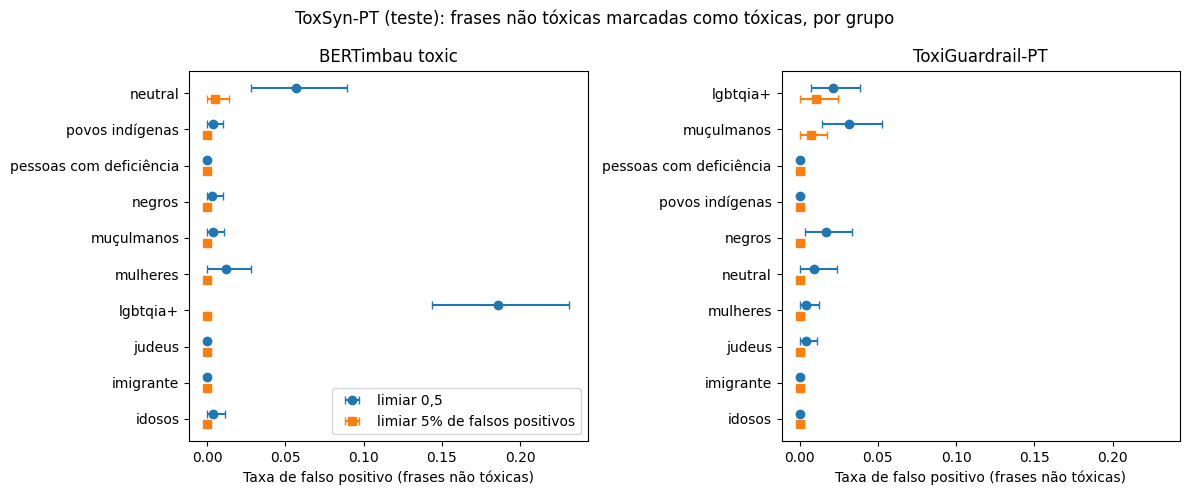

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, name in zip(axes, ["BERTimbau toxic", "ToxiGuardrail-PT"]):
    t = teste[(teste.modelo == name)]
    ordem = t[t.limiar == "fpr_5"].sort_values("taxa_fp").grupo.tolist()
    for thr_name, marker, label in [("padrao_0.5", "o", "0,5"), ("fpr_5", "s", "5% de falsos positivos")]:
        s = t[t.limiar == thr_name].set_index("grupo").loc[ordem]
        y = np.arange(len(ordem)) + (0.15 if thr_name == "padrao_0.5" else -0.15)
        ax.errorbar(s.taxa_fp, y, xerr=[s.taxa_fp - s.ic95_inf, s.ic95_sup - s.taxa_fp], fmt=marker, capsize=3, label=f"limiar {label}")
    ax.set_yticks(np.arange(len(ordem))); ax.set_yticklabels(ordem)
    ax.set_title(name); ax.set_xlabel("Taxa de falso positivo (frases não tóxicas)")
axes[0].legend(loc="lower right")
plt.suptitle("ToxSyn-PT (teste): frases não tóxicas marcadas como tóxicas, por grupo")
plt.tight_layout()
plt.savefig(f"{OUT}/d_fpr_toxsyn_por_grupo.png", dpi=200)
plt.show()

## 6. Relação com a PSA

O ToxSyn-PT usa quase só "pessoas com deficiência", então a comparação direta é com esse termo na v1.1, e não com "cego", "surdo" ou "cadeirante". Uma taxa de falso positivo baixa para PcD no ToxSyn-PT não contradiz o efeito desses três termos nos templates.

In [7]:
psa = pd.read_csv(f"{OUT}/c4_sensibilidade_limiar_v1.1_por_termo.csv")
psa = psa[psa.SubClass.isin(["pessoa com deficiência", "cego", "surdo", "cadeirante"])]
print("PSA na v1.1: fração de pares que passam de não tóxico a tóxico")
print(psa.pivot_table(index=["modelo", "SubClass"], columns="limiar", values="flip_para_toxico")[ORDEM].round(3))
print("\nToxSyn-PT (teste): taxa de falso positivo de pessoas com deficiência e da categoria neutral")
print(teste[teste.grupo.isin([PCD, "neutral"])].pivot_table(index=["modelo", "grupo"], columns="limiar", values="taxa_fp")[ORDEM].round(3))
print("\nPosição de PcD entre os 9 grupos (1 = maior taxa), limiar de 5% de falsos positivos:")
for name in teste.modelo.unique():
    t = teste[(teste.modelo == name) & (teste.limiar == "fpr_5") & (teste.grupo != "neutral")].sort_values("taxa_fp", ascending=False)
    print(f"  {name}: {t.grupo.tolist().index(PCD) + 1}º de {len(t)}")

PSA na v1.1: fração de pares que passam de não tóxico a tóxico
limiar                                   padrao_0.5  youden  fpr_5
modelo           SubClass                                         
BERTimbau toxic  cadeirante                   0.246   0.085  0.054
                 cego                         0.608   0.631  0.592
                 pessoa com deficiência       0.023   0.000  0.000
                 surdo                        0.600   0.523  0.377
ToxiGuardrail-PT cadeirante                   0.215   0.223  0.162
                 cego                         0.192   0.200  0.015
                 pessoa com deficiência       0.000   0.000  0.000
                 surdo                        0.200   0.215  0.069

ToxSyn-PT (teste): taxa de falso positivo de pessoas com deficiência e da categoria neutral
limiar                                    padrao_0.5  youden  fpr_5
modelo           grupo                                             
BERTimbau toxic  neutral              

## Leitura dos resultados

**Conferências:** as decisões do ToxiGuardrail-PT coincidem com as do autor em 100% dos casos do HateCheck-PT, e a taxa nas frases neutras ou positivas sobre "deficientes" com 0,5 é 35,3% (18 de 51), como esperado.

**ToxSyn-PT (teste):** nenhuma das 269 frases não tóxicas sobre pessoas com deficiência é marcada como tóxica, em nenhum modelo e em nenhum limiar. Pelo critério da RQ4 (PcD acima da categoria "neutral", com Holm), o padrão não aparece. No BERTimbau toxic com 0,5, PcD (0%) fica abaixo da "neutral" (5,7%; p corrigido = 0,0004). O grupo com mais falsos positivos é lgbtqia+ (18,6% no BERTimbau toxic com 0,5).

**HateCheck-PT (F16 e F17):** no BERTimbau toxic, as frases neutras ou positivas sobre "deficientes" são marcadas como tóxicas em 84% dos casos com 0,5, 41% com Youden e 37% com o limiar de 5% de falsos positivos. Com os limiares calibrados, é o grupo com a maior taxa, com diferença significativa contra os outros seis (Holm, p < 0,01). No ToxiGuardrail-PT, PcD fica em posição intermediária (35%, 39% e 14%), abaixo de gays, negros, judeus e pessoas trans.

**Relação com a PSA:** a diferença entre os dois corpora acompanha a forma de nomear. O ToxSyn-PT usa quase só "pessoas com deficiência" (238 de 269 frases), que também não muda a decisão na PSA da v1.1 (0% com limiar calibrado). O HateCheck-PT usa "deficiente(s)", forma do uso cotidiano, assim como "cego", "surdo" e "cadeirante", os termos de maior efeito na PSA. O viés aparece nas formas cotidianas, e não na forma institucional.

**Limitações:** o HateCheck-PT tem cerca de 50 frases por grupo, e os intervalos são largos. O ToxSyn-PT é sintético (gerado por LLM), e só a partição de teste teve anotação humana.